<a href="https://colab.research.google.com/github/kinantinurani/ADV_KKA/blob/main/Tugas_Proyek_AVD_Kelompok7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

kelompok 7
1. Kinanti elok hati nurani (15)
2. Muhammad habib zain (17)
3. Nasheed axel saputra (20)
3. Zeindra dwi meilano (29)

In [ ]:
 import pandas as pd

# 1. Memuat dataset kalian
df = pd.read_csv('Mall_Customers.csv')
if 'Genre' in df.columns:
    df = df.rename(columns={'Genre': 'Gender'})

# 2. Eksplorasi awal (persis seperti langkah di modul)
print("--- 5 BARIS PERTAMA ---")
print(df.head())

print("\n--- INFO TIPE DATA & DATA KOSONG ---")
print(df.info())

print("\n--- RINGKASAN STATISTIK ---")
print(df.describe())

# 3. Rata-rata Skor Belanja per Kategori (Gender)
rata_kategori = df.groupby('Gender')['Spending Score (1-100)'].mean()
print("\n--- RATA-RATA SKOR BELANJA PER GENDER ---")
print(rata_kategori.sort_values(ascending=False))

--- 5 BARIS PERTAMA ---
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

--- INFO TIPE DATA & DATA KOSONG ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.

1. Kategori dengan rata-rata tertinggi:
Kategori Female (Wanita) punya rata-rata skor belanja paling tinggi yaitu 51,53, sedikit di atas Male (Pria) yang rata-ratanya 48,51.

2. Cek data kosong (missing value):Tidak ada data yang kosong. Cara ceknya dari df.info() tinggal lihat bagian Non-Null Count-nya; semua kolom angkanya 200 non-null, sama dengan jumlah total baris data (200 entries), jadi datanya lengkap semua.

3. Perbandingan mean dan median:
Pada kolom Spending Score, nilai mean (50,20) dan median (50,00) hampir sama persis. Artinya sebaran datanya cukup merata/simetris dan tidak terlalu ketarik sama nilai ekstrem (outlier).

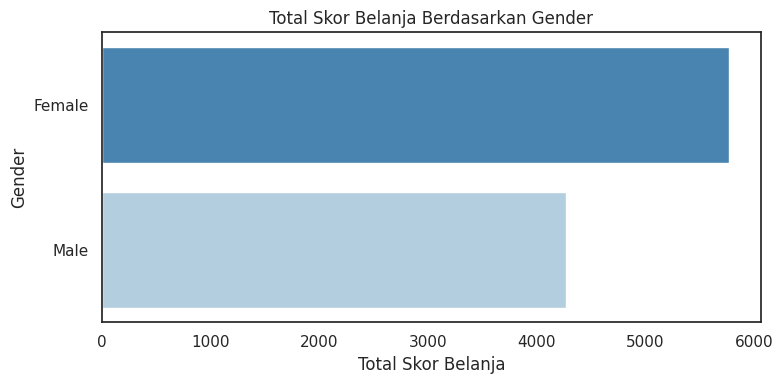

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Hitung total skor belanja per Gender
total_kategori = df.groupby('Gender')['Spending Score (1-100)'].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(x=total_kategori.values, y=total_kategori.index, hue=total_kategori.index, palette='Blues_r')
plt.title('Total Skor Belanja Berdasarkan Gender')
plt.xlabel('Total Skor Belanja')
plt.ylabel('Gender')
plt.tight_layout()
plt.show()

1. Kategori yang menyumbang tertinggi dan terendah:
Kategori Female (Wanita) menyumbang total skor belanja tertinggi sebesar 5.771, sedangkan kategori Male (Pria) paling rendah dengan total 4.269.   

2. Rekomendasi bisnis berdasarkan grafik:
Manajemen sebaiknya memperbanyak promo, diskon, atau stok produk yang ditargetkan khusus untuk pelanggan wanita karena mereka penyumbang transaksi terbesar, sekaligus membuat promo bundling atau event khusus pria agar minat belanja pelanggan pria ikut naik.   

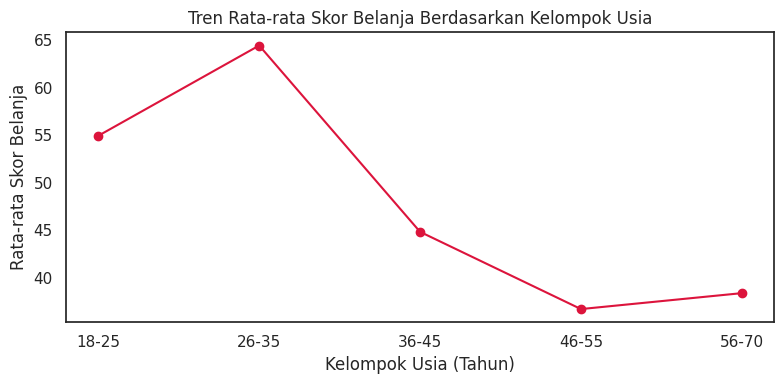

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Kelompokkan usia menjadi beberapa rentang untuk melihat tren
df['Kelompok_Usia'] = pd.cut(df['Age'], bins=[15, 25, 35, 45, 55, 70], labels=['18-25', '26-35', '36-45', '46-55', '56-70'])
tren_usia = df.groupby('Kelompok_Usia', observed=False)['Spending Score (1-100)'].mean()

plt.figure(figsize=(8, 4))
plt.plot(tren_usia.index.astype(str), tren_usia.values, marker='o', color='crimson')
plt.title('Tren Rata-rata Skor Belanja Berdasarkan Kelompok Usia')
plt.xlabel('Kelompok Usia (Tahun)')
plt.ylabel('Rata-rata Skor Belanja')
plt.tight_layout()
plt.show()

1. Kelompok (pengganti bulan) apa yang memiliki skor belanja tertinggi? Apa kemungkinan penyebabnya?
Kelompok usia 26–35 tahun memiliki rata-rata skor belanja paling tinggi (64,45). Kemungkinan penyebabnya karena pada rentang usia ini pelanggan umumnya sudah bekerja dan memiliki penghasilan sendiri, serta cenderung lebih konsumtif mengikuti tren gaya hidup dibandingkan kelompok usia lainnya.  

2. Trennya cenderung turun seiring bertambahnya usia. Setelah mencapai puncak di usia 26–35 tahun, rata-rata skor belanja turun cukup drastis pada usia 36–45 tahun (44,83) hingga titik terendah di usia 46–55 tahun (36,70), karena pada usia lebih matang pelanggan biasanya lebih selektif dan fokus pada kebutuhan keluarga/tabungan.

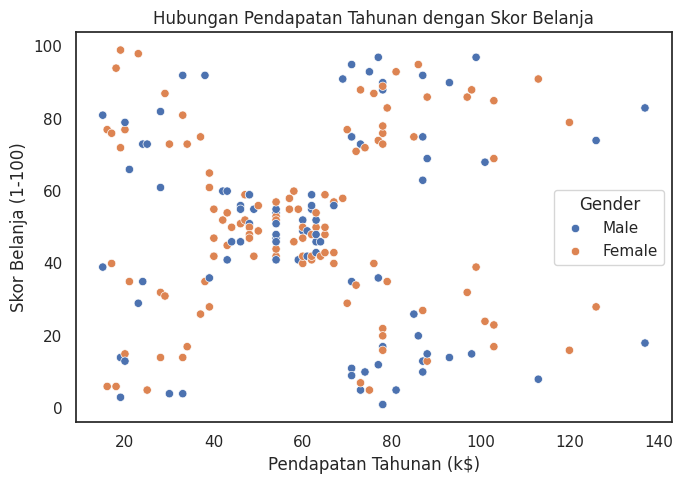

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

if 'Genre' in df.columns:
    df = df.rename(columns={'Genre': 'Gender'})

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)', hue='Gender')
plt.title('Hubungan Pendapatan Tahunan dengan Skor Belanja')
plt.xlabel('Pendapatan Tahunan (k$)')
plt.ylabel('Skor Belanja (1-100)')
plt.tight_layout()
plt.show()

1. Pola hubungan kedua variabel (positif/negatif/tidak berhubungan):
Secara umum polanya tidak berhubungan secara lurus (korelasi sangat lemah / mendekati 0), karena titik-titiknya menyebar membentuk 5 kelompok terpisah. Pendapatan yang tinggi tidak selalu membuat skor belanja ikut tinggi (ada yang pendapatannya besar tapi jarang belanja, ada juga yang pendapatannya kecil tapi sering belanja).   

2. Titik data yang jauh dari pola umum (outlier) beserta kategorinya:
Ada, terlihat 2 titik yang paling jauh di sisi kanan grafik pada angka pendapatan $137k (skor belanja 18 dan 83). Dari warnanya, kedua outlier tersebut berasal dari kategori Male (Pria).   

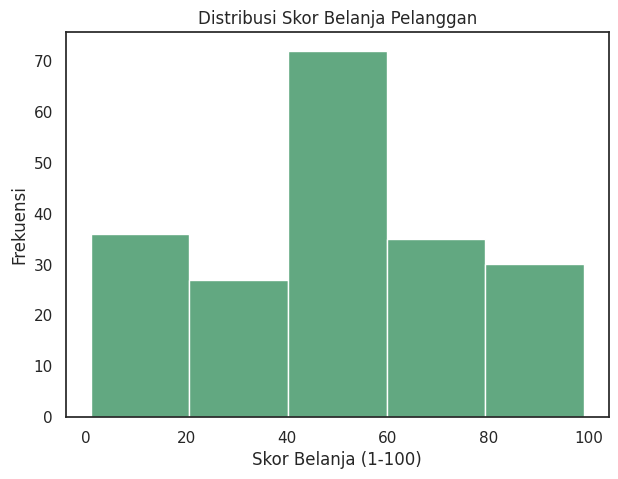

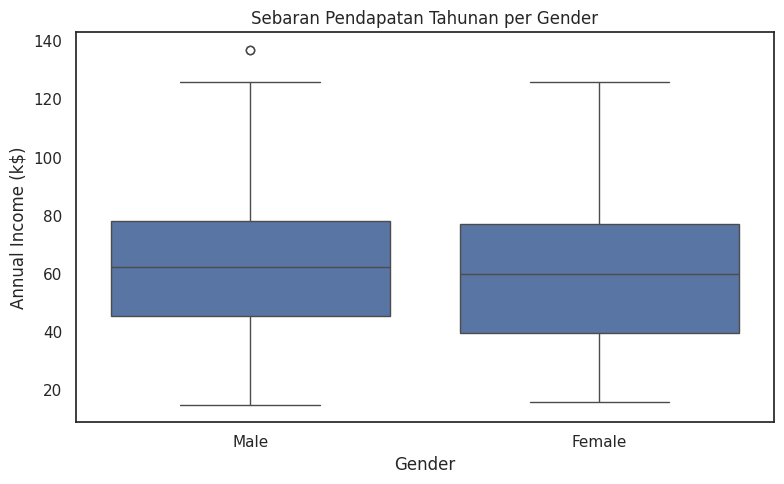

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

if 'Genre' in df.columns:
    df = df.rename(columns={'Genre': 'Gender'})

# Histogram distribusi skor belanja pelanggan
plt.figure(figsize=(7, 5))
sns.histplot(df['Spending Score (1-100)'], bins=5, color='seagreen')
plt.title('Distribusi Skor Belanja Pelanggan')
plt.xlabel('Skor Belanja (1-100)')
plt.ylabel('Frekuensi')
plt.show()

# Boxplot pendapatan tahunan per Gender (deteksi outlier)
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Gender', y='Annual Income (k$)')
plt.title('Sebaran Pendapatan Tahunan per Gender')
plt.tight_layout()
plt.show()

1. Bentuk distribusi skor belanja (pengganti rating pelanggan):
Distribusinya cenderung merata di tengah (simetris), dengan frekuensi paling banyak menumpuk di sekitar skor menengah (40–60). Jumlah pelanggan dengan skor belanja sangat tinggi maupun sangat rendah hampir seimbang.   

2. Kategori yang memiliki outlier di boxplot dan kemungkinan penyebabnya:
Kategori Male (Pria) yang memiliki titik outlier di atas garis boxplot (pada angka pendapatan $137k). Kemungkinan penyebabnya karena ada pelanggan pria dari kalangan pengusaha atau eksekutif berpenghasilan tinggi yang jauh di atas rata-rata pendapatan pelanggan mal pada umumnya.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

if 'Genre' in df.columns:
    df = df.rename(columns={'Genre': 'Gender'})

total_kategori = df.groupby('Gender')['Spending Score (1-100)'].sum().sort_values(ascending=False)
df['Kelompok_Usia'] = pd.cut(df['Age'], bins=[15, 25, 35, 45, 55, 70], labels=['18-25', '26-35', '36-45', '46-55', '56-70'])
tren_usia = df.groupby('Kelompok_Usia', observed=False)['Spending Score (1-100)'].mean()

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.barplot(x=total_kategori.values, y=total_kategori.index, ax=axes[0,0])
axes[0,0].set_title('Total Skor Belanja per Gender')

axes[0,1].plot(tren_usia.index.astype(str), tren_usia.values, marker='o')
axes[0,1].set_title('Tren Skor Belanja per Kelompok Usia')

sns.histplot(df['Spending Score (1-100)'], bins=5, ax=axes[1,0])
axes[1,0].set_title('Distribusi Skor Belanja Pelanggan')

sns.boxplot(data=df, x='Gender', y='Annual Income (k$)', ax=axes[1,1])
axes[1,1].set_title('Sebaran Pendapatan per Gender')

plt.tight_layout()
plt.show()

1. Keuntungan dashboard dibandingkan grafik terpisah:
Lebih praktis karena semua data langsung terlihat dalam satu layar tanpa perlu scroll bolak-balik, sehingga lebih cepat dibaca dan dibandingkan.

2. Keputusan bisnis berdasarkan dashboard:
Memfokuskan promo dan stok barang pada pelanggan wanita serta kelompok usia 26–35 tahun karena skor belanjanya paling tinggi, sekaligus membuat promo khusus member untuk menarik pelanggan berpendapatan tinggi agar lebih sering belanja.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur tema visualisasi agar bersih dan modern
sns.set_theme(style='white')

# 1. Memuat dataset
df = pd.read_csv('Mall_Customers.csv')

# 2. Memperbaiki nama kolom 'Genre' menjadi 'Gender' agar tidak eror
if 'Genre' in df.columns:
    df = df.rename(columns={'Genre': 'Gender'})

# 3. Eksplorasi & Pembersihan Data
print("--- 5 DATA PERTAMA ---")
print(df.head())

print("\n--- CEK DATA KOSONG (MISSING VALUE) ---")
print(df.isnull().sum())

print("\n--- CEK DATA DUPLIKAT ---")
print("Jumlah data duplikat:", df.duplicated().sum())

print("\n--- RINGKASAN STATISTIK AWAL ---")
print(df.describe().round(2))

--- 5 DATA PERTAMA ---
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

--- CEK DATA KOSONG (MISSING VALUE) ---
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

--- CEK DATA DUPLIKAT ---
Jumlah data duplikat: 0

--- RINGKASAN STATISTIK AWAL ---
       CustomerID     Age  Annual Income (k$)  Spending Score (1-100)
count      200.00  200.00              200.00                  200.00
mean       100.50   38.85               60.56                   50.20
std         57.88   13.97               26.26                 

In [ ]:
total_pelanggan = len(df)
rata_usia = df['Age'].mean()
median_pendapatan = df['Annual Income (k$)'].median()
std_pendapatan = df['Annual Income (k$)'].std()
proporsi_gender = df['Gender'].value_counts(normalize=True) * 100
rata_spending_gender = df.groupby('Gender')['Spending Score (1-100)'].mean()

print("=== 5 STATISTIK DESKRIPTIF KUNCI ===")
print(f"1. Total Pelanggan     : {total_pelanggan} orang")
print(f"2. Rata-rata Usia      : {rata_usia:.1f} tahun")
print(f"3. Median Pendapatan   : ${median_pendapatan:.2f}k (Std Dev: ${std_pendapatan:.2f}k)")
print("4. Proporsi Gender (%):")
print(proporsi_gender.round(1).to_string())
print("\n5. Rata-rata Skor Belanja per Gender:")
print(rata_spending_gender.round(1).to_string())

=== 5 STATISTIK DESKRIPTIF KUNCI ===
1. Total Pelanggan     : 200 orang
2. Rata-rata Usia      : 38.9 tahun
3. Median Pendapatan   : $61.50k (Std Dev: $26.26k)
4. Proporsi Gender (%):
Gender
Female    56.0
Male      44.0

5. Rata-rata Skor Belanja per Gender:
Gender
Female    51.5
Male      48.5


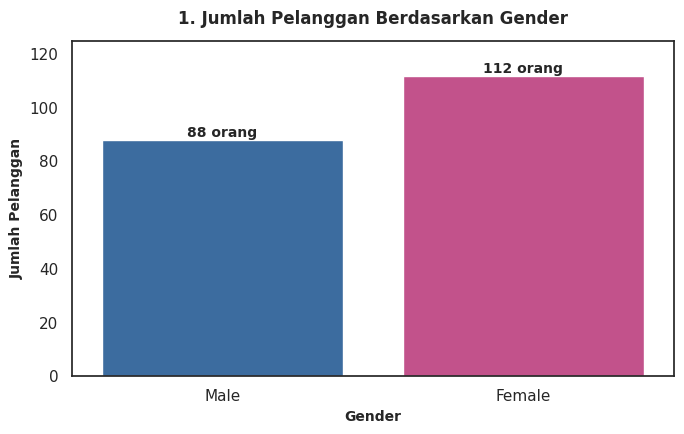

In [ ]:
plt.figure(figsize=(7, 4.5), dpi=100)
ax1 = sns.countplot(data=df, x='Gender', hue='Gender', palette={'Male': '#2B6CB0', 'Female': '#D53F8C'})

plt.title('1. Jumlah Pelanggan Berdasarkan Gender', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Gender', fontsize=10, fontweight='bold')
plt.ylabel('Jumlah Pelanggan', fontsize=10, fontweight='bold')

# Label angka di atas batang
for p in ax1.patches:
    h = p.get_height()
    if h > 0:
        ax1.annotate(f'{int(h)} orang', (p.get_x() + p.get_width() / 2., h),
                     ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.ylim(0, 125)
plt.tight_layout()
plt.show()

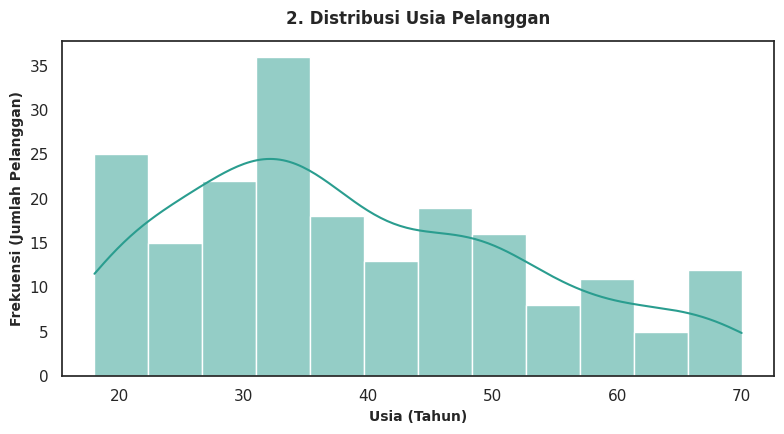

In [ ]:
plt.figure(figsize=(8, 4.5), dpi=100)
sns.histplot(df['Age'], kde=True, bins=12, color='#2A9D8F')

plt.title('2. Distribusi Usia Pelanggan', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Usia (Tahun)', fontsize=10, fontweight='bold')
plt.ylabel('Frekuensi (Jumlah Pelanggan)', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

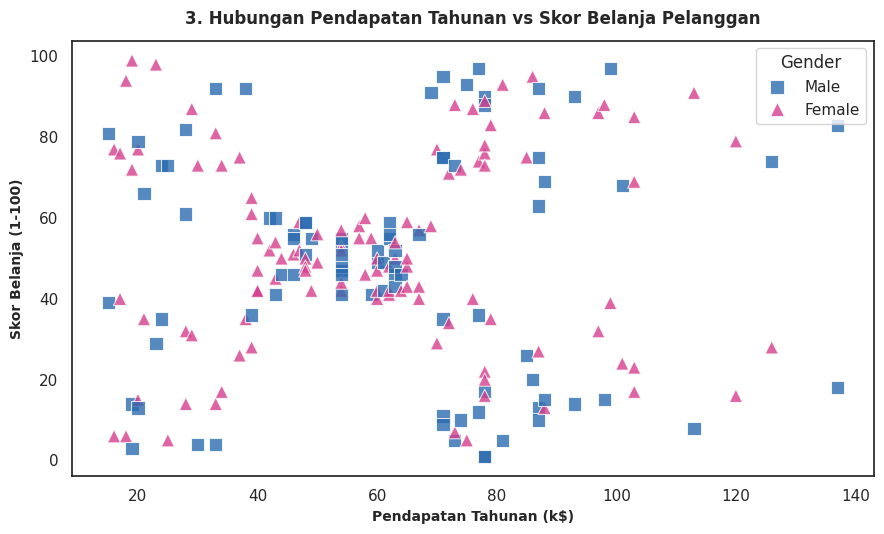

In [ ]:
plt.figure(figsize=(9, 5.5), dpi=100)

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Gender',
    style='Gender',
    markers={'Male': 's', 'Female': '^'}, # 's' = kotak, '^' = segitiga
    palette={'Male': '#2B6CB0', 'Female': '#D53F8C'},
    s=90,
    alpha=0.8
)

plt.title('3. Hubungan Pendapatan Tahunan vs Skor Belanja Pelanggan', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Pendapatan Tahunan (k$)', fontsize=10, fontweight='bold')
plt.ylabel('Skor Belanja (1-100)', fontsize=10, fontweight='bold')
plt.grid(False)
plt.legend(title='Gender', frameon=True, facecolor='white', loc='upper right')

plt.tight_layout()
plt.show()

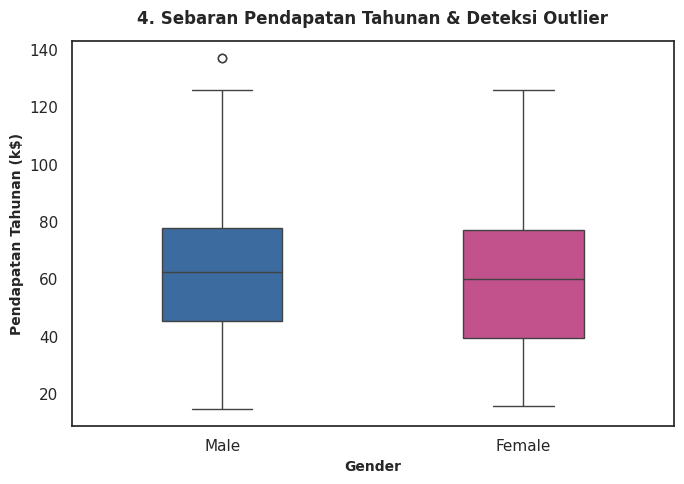

Batas Atas Normal (Q3 + 1.5*IQR): $132.75k
Data Outlier yang Terdeteksi:
 CustomerID Gender  Age  Annual Income (k$)  Spending Score (1-100)
        199   Male   32                 137                      18
        200   Male   30                 137                      83


In [ ]:
plt.figure(figsize=(7, 5), dpi=100)
sns.boxplot(data=df, x='Gender', y='Annual Income (k$)', hue='Gender', palette={'Male': '#2B6CB0', 'Female': '#D53F8C'}, width=0.4)

plt.title('4. Sebaran Pendapatan Tahunan & Deteksi Outlier', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Gender', fontsize=10, fontweight='bold')
plt.ylabel('Pendapatan Tahunan (k$)', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

# Perhitungan Matematis IQR untuk Deteksi Outlier
Q1 = df['Annual Income (k$)'].quantile(0.25)
Q3 = df['Annual Income (k$)'].quantile(0.75)
IQR = Q3 - Q1
batas_atas = Q3 + 1.5 * IQR

outliers = df[df['Annual Income (k$)'] > batas_atas]
print(f"Batas Atas Normal (Q3 + 1.5*IQR): ${batas_atas:.2f}k")
print("Data Outlier yang Terdeteksi:")
print(outliers[['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']].to_string(index=False))

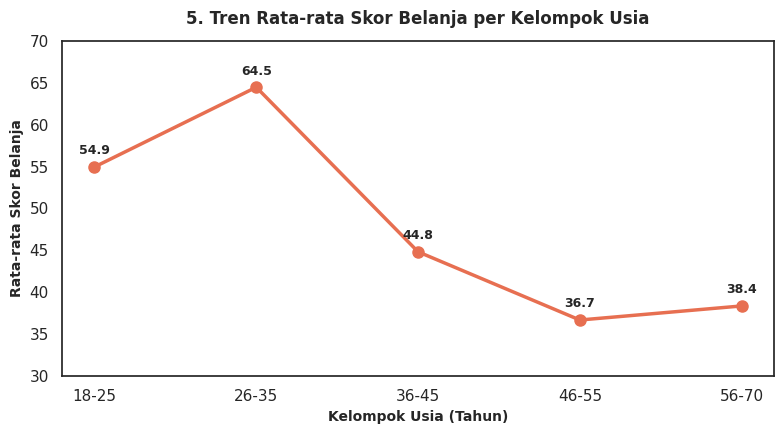

In [ ]:
# Mengelompokkan usia ke dalam rentang kategori
df['Kelompok Usia'] = pd.cut(df['Age'], bins=[15, 25, 35, 45, 55, 70], labels=['18-25', '26-35', '36-45', '46-55', '56-70'])
trend_usia = df.groupby('Kelompok Usia', observed=False)['Spending Score (1-100)'].mean().reset_index()

plt.figure(figsize=(8, 4.5), dpi=100)
plt.plot(trend_usia['Kelompok Usia'], trend_usia['Spending Score (1-100)'], marker='o', markersize=8, linewidth=2.5, color='#E76F51')

# Menampilkan angka di setiap titik
for i, txt in enumerate(trend_usia['Spending Score (1-100)']):
    plt.annotate(f'{txt:.1f}', (trend_usia['Kelompok Usia'][i], txt + 1.5), ha='center', fontsize=9, fontweight='bold')

plt.title('5. Tren Rata-rata Skor Belanja per Kelompok Usia', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Kelompok Usia (Tahun)', fontsize=10, fontweight='bold')
plt.ylabel('Rata-rata Skor Belanja', fontsize=10, fontweight='bold')
plt.ylim(30, 70)

plt.tight_layout()
plt.show()

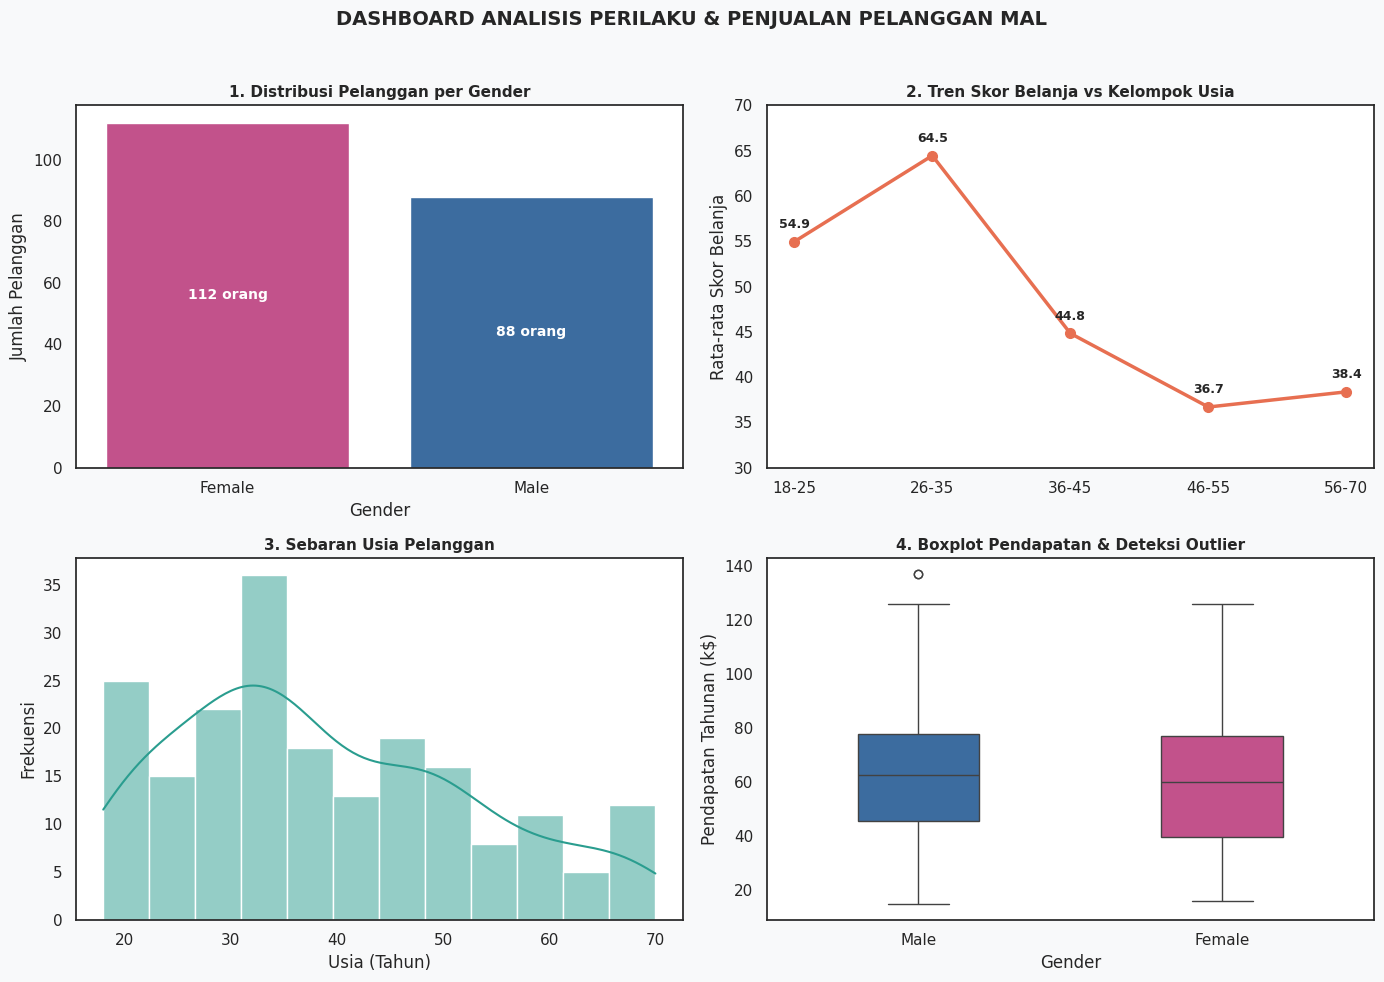

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=100)
fig.patch.set_facecolor('#F8F9FA')

# 1. Bar Chart
sns.barplot(x=df['Gender'].value_counts().index, y=df['Gender'].value_counts().values, ax=axes[0,0],
            palette=['#D53F8C', '#2B6CB0'], hue=df['Gender'].value_counts().index)
axes[0,0].set_title('1. Distribusi Pelanggan per Gender', fontsize=11, fontweight='bold')
axes[0,0].set_ylabel('Jumlah Pelanggan')
for p in axes[0,0].patches:
    if p.get_height() > 0:
        axes[0,0].annotate(f'{int(p.get_height())} orang', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                           ha='center', va='center', fontsize=10, fontweight='bold', color='white')

# 2. Line Chart
axes[0,1].plot(trend_usia['Kelompok Usia'], trend_usia['Spending Score (1-100)'], marker='o', markersize=7, color='#E76F51', linewidth=2.5)
axes[0,1].set_title('2. Tren Skor Belanja vs Kelompok Usia', fontsize=11, fontweight='bold')
axes[0,1].set_ylabel('Rata-rata Skor Belanja')
axes[0,1].set_ylim(30, 70)
for i, txt in enumerate(trend_usia['Spending Score (1-100)']):
    axes[0,1].annotate(f'{txt:.1f}', (trend_usia['Kelompok Usia'][i], txt + 1.5), ha='center', fontsize=9, fontweight='bold')

# 3. Histogram
sns.histplot(df['Age'], kde=True, ax=axes[1,0], color='#2A9D8F', bins=12)
axes[1,0].set_title('3. Sebaran Usia Pelanggan', fontsize=11, fontweight='bold')
axes[1,0].set_xlabel('Usia (Tahun)')
axes[1,0].set_ylabel('Frekuensi')

# 4. Boxplot
sns.boxplot(data=df, x='Gender', y='Annual Income (k$)', ax=axes[1,1], palette={'Male': '#2B6CB0', 'Female': '#D53F8C'}, hue='Gender', width=0.4)
axes[1,1].set_title('4. Boxplot Pendapatan & Deteksi Outlier', fontsize=11, fontweight='bold')
axes[1,1].set_ylabel('Pendapatan Tahunan (k$)')

plt.suptitle('DASHBOARD ANALISIS PERILAKU & PENJUALAN PELANGGAN MAL', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()